# 第6章　ベイズ最適化の実行

第1章の合成材料を、今回は $x\in[0,1]$ の連続範囲で最適化します。Sobolの初期4点と追加4点で、手動ループとStudyの試行管理を比較します。この章の測定は決定論的です。GPでは既定の観測分散の推定を使用します。

In [1]:
import json
from time import perf_counter

import matplotlib.pyplot as plt
import torch
from botorch.acquisition.analytic import LogExpectedImprovement, PosteriorMean
from robotorchan.models import SingleTaskGP
from robotorchan.optim import optimize_acqf
from robotorchan.study import TrialState, create_study
from torch.quasirandom import SobolEngine

from experiment import BLUE, DTYPE, ORANGE, QUALITY, SEED, material_strength, save_figure, setup

setup()
torch.set_default_dtype(DTYPE)
bounds = torch.tensor([[0.0], [1.0]], dtype=DTYPE)
n_initial, n_additional = 4, 4
solver = {"num_restarts": 6, "raw_samples": 64, "options": {"seed": SEED}}
x_initial = SobolEngine(1, scramble=True, seed=SEED).draw_base2(2)
y_initial = material_strength(x_initial)

model = SingleTaskGP(x_initial, y_initial)
model.fit()
acquisition = LogExpectedImprovement(model, best_f=y_initial.max())
suggestion, _ = optimize_acqf(acquisition, bounds, q=1, **solver)
measured = material_strength(suggestion)
print("初期温度 [°C]:", (140 + 40 * x_initial[:, 0]).tolist())
print("次の温度と測定値 [°C, MPa]:", 140 + 40 * suggestion.item(), measured.item())

初期温度 [°C]: [151.78480569273233, 164.5459970831871, 176.3834585621953, 149.79414030909538]
次の温度と測定値 [°C, MPa]: 140.0 74.0


## 6.2 予算まで更新する

最初のコードで測った候補を登録し、同じ順序で再学習を繰り返します。モデリングや候補計算でGPを内部評価しても、目的関数を測る回数は増えません。

In [2]:
train_x = torch.cat((x_initial, suggestion))
train_y = torch.cat((y_initial, measured))
manual_started = perf_counter()
for _ in range(1, n_additional):
    model = SingleTaskGP(train_x, train_y)
    model.fit()
    acquisition = LogExpectedImprovement(model, best_f=train_y.max())
    point, _ = optimize_acqf(acquisition, bounds, q=1, **solver)
    value = material_strength(point)
    train_x = torch.cat((train_x, point))
    train_y = torch.cat((train_y, value))
print("初期点と最初の追加点を除いた残りの反復時間 [s]:", round(perf_counter() - manual_started, 3))
assert len(train_x) == len(train_y) == n_initial + n_additional

初期点と最初の追加点を除いた残りの反復時間 [s]: 0.355


## 6.4 Studyで候補と結果を管理する

`ask()` は実験状態を `RUNNING` にします。測定が成功した時点で `tell()` に強度を渡し、状態が `COMPLETE` になります。同じSobolシード・代理モデル・獲得関数・候補計算条件を設定し、手動版と初期設計・予算を照合します。

In [3]:
study = create_study(
    search_space={"x": (0.0, 1.0)},
    direction="maximize",
    model=SingleTaskGP,
    acquisition=LogExpectedImprovement,
    n_initial_trials=n_initial,
    seed=SEED,
    optimizer_kwargs=solver,
)

for _ in range(n_initial + n_additional):
    trial = study.ask()
    assert trial.state is TrialState.RUNNING
    point = torch.tensor([[trial.params["x"]]], dtype=DTYPE)
    value = material_strength(point).item()
    completed = study.tell(trial, value)
    assert completed.state is TrialState.COMPLETE

done = [t for t in study.trials if t.state is TrialState.COMPLETE]
study_x = torch.tensor([[t.params["x"]] for t in done], dtype=DTYPE)
study_y = torch.tensor([[t.value] for t in done], dtype=DTYPE)
torch.testing.assert_close(study_x[:n_initial], x_initial)
torch.testing.assert_close(study_y[:n_initial], y_initial)
assert len(done) == n_initial + n_additional
print("Studyの最良観測 [MPa]:", study.best_value)

Studyの最良観測 [MPa]: 79.7566844419405


## 6.5 失敗した試行と最後の推薦を扱う

装置のタイムアウトを1件記録し、予算を消費する試行と、学習に入る観測の数が異なる場合を確認します。この例では残りの予算内で再開します。終了後は事後平均を用いた推薦を作り、測定済みの最良点と区別して記録します。

In [4]:
with_failure = create_study(
    search_space={"x": (0.0, 1.0)}, n_initial_trials=4, seed=SEED,
)

fail_number = 1


def objective(trial):
    if trial.number == fail_number:
        raise TimeoutError("測定応答が得られなかった想定")
    return material_strength(torch.tensor([[trial.params["x"]]], dtype=DTYPE)).item()

with_failure.optimize(objective, n_trials=4, catch=(TimeoutError,))
states = [trial.state.name for trial in with_failure.trials]
expected_states = ["COMPLETE"] * 4
expected_states[fail_number] = "FAIL"
assert states == expected_states
assert with_failure.trials[fail_number].value is None

terminal_model = SingleTaskGP(train_x, train_y)
terminal_model.fit()
recommendation, recommendation_mean = optimize_acqf(
    PosteriorMean(terminal_model), bounds, q=1, **solver,
)
index_best = int(train_y[:, 0].argmax())
recommended_temperature = 140 + 40 * recommendation.item()
closest_distance = (train_x - recommendation).abs().min().item()
print("4試行の状態:", states)
print("最良観測の温度と強度:", 140 + 40 * train_x[index_best].item(), train_y[index_best].item())
print("推薦温度と事後平均:", recommended_temperature, recommendation_mean.item())

4試行の状態: ['COMPLETE', 'FAIL', 'COMPLETE', 'COMPLETE']
最良観測の温度と強度: 152.28031605358976 79.75668456864597
推薦温度と事後平均: 151.87708753445753 79.71047548159976


{
  "initial_count": 4,
  "additional_count": 4,
  "initial_temperatures_c": [
    151.78480569273233,
    164.5459970831871,
    176.3834585621953,
    149.79414030909538
  ],
  "first_temperature_c": 140.0,
  "first_mpa": 74.0,
  "manual_temperatures_c": [
    151.78480569273233,
    164.5459970831871,
    176.3834585621953,
    149.79414030909538,
    140.0,
    152.27443452700905,
    152.28031605358976,
    152.00890934537696
  ],
  "study_temperatures_c": [
    151.78480569273233,
    164.5459970831871,
    176.3834585621953,
    149.79414030909538,
    140.0,
    152.2744345831197,
    152.2803156157002,
    152.0089087688599
  ],
  "max_path_difference_x": 1.4412926074847121e-08,
  "manual_best_mpa": 79.75668456864597,
  "manual_best_temperature_c": 152.28031605358976,
  "study_best_mpa": 79.7566844419405,
  "recommended_temperature_c": 151.87708753445753,
  "recommended_mean_mpa": 79.71047548159976,
  "measurement_distance_x": 0.002307046043129868,
  "failure_states": [
    "C

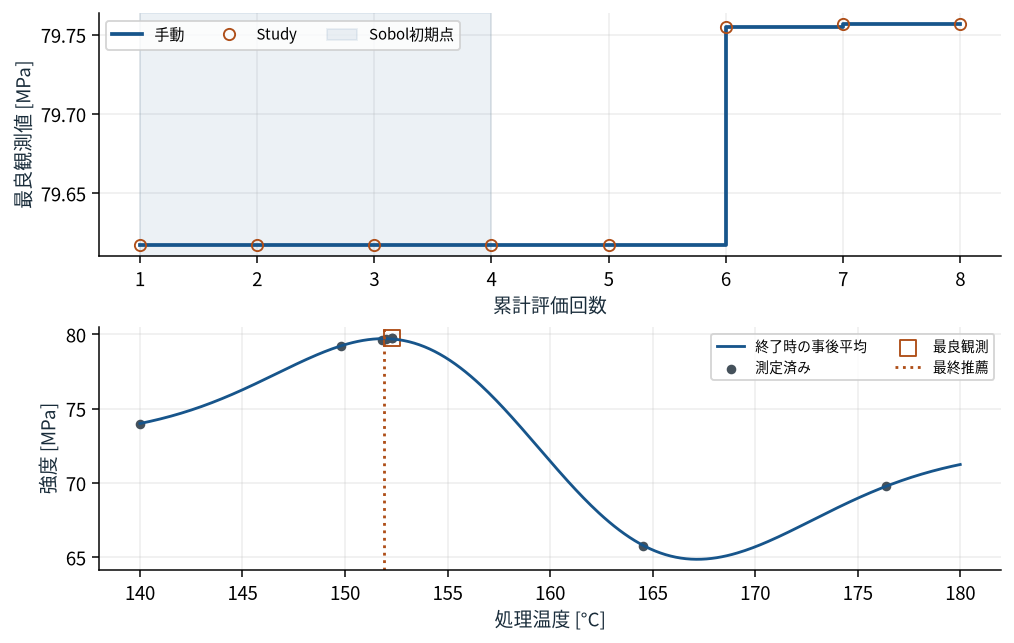

In [5]:
fig, (ax, bx) = plt.subplots(2, 1, figsize=(7.4, 4.65), layout="constrained")
numbers = range(1, len(train_y) + 1)
ax.step(numbers, train_y[:, 0].cummax(0).values, where="post",
        color=BLUE, linewidth=2, label="手動")
ax.plot(numbers, study_y[:, 0].cummax(0).values, "o", color=ORANGE,
        fillstyle="none", label="Study")
ax.axvspan(1, n_initial, color=BLUE, alpha=0.08, label="Sobol初期点")
ax.set(xlabel="累計評価回数", ylabel="最良観測値 [MPa]")
ax.legend(ncols=3, fontsize=8)

grid = torch.linspace(0, 1, 321, dtype=DTYPE).unsqueeze(-1)
with torch.no_grad():
    predicted = terminal_model.posterior(grid).mean[:, 0]
bx.plot(140 + 40 * grid[:, 0], predicted, color=BLUE, label="終了時の事後平均")
bx.scatter(140 + 40 * train_x[:, 0], train_y[:, 0], color="#45515b", s=17, label="測定済み")
bx.scatter(140 + 40 * train_x[index_best].item(), train_y[index_best].item(),
           marker="s", facecolors="none", edgecolors=ORANGE, s=75, label="最良観測")
bx.axvline(recommended_temperature, color=ORANGE, linestyle=":", label="最終推薦")
bx.set(xlabel="処理温度 [°C]", ylabel="強度 [MPa]")
bx.legend(ncols=2, fontsize=7.3)
save_figure(fig, "ch06_bo_loop")

metrics = {
    "initial_count": n_initial, "additional_count": n_additional,
    "initial_temperatures_c": (140 + 40 * x_initial[:, 0]).tolist(),
    "first_temperature_c": 140 + 40 * suggestion.item(),
    "first_mpa": measured.item(),
    "manual_temperatures_c": (140 + 40 * train_x[:, 0]).tolist(),
    "study_temperatures_c": (140 + 40 * study_x[:, 0]).tolist(),
    "max_path_difference_x": (train_x - study_x).abs().max().item(),
    "manual_best_mpa": train_y[index_best].item(),
    "manual_best_temperature_c": 140 + 40 * train_x[index_best].item(),
    "study_best_mpa": study.best_value,
    "recommended_temperature_c": recommended_temperature,
    "recommended_mean_mpa": recommendation_mean.item(),
    "measurement_distance_x": closest_distance,
    "failure_states": states,
}
(QUALITY / "ch06_metrics.json").write_text(json.dumps(metrics, indent=2) + "\n", encoding="utf-8")
print(json.dumps(metrics, indent=2))

## 章末演習
1. **確認。** 初期4点と追加4点のうち、GPの学習だけに消費する測定はいくつですか。最終推薦の温度を確認測定した場合も数えましょう。
2. **操作。** 失敗の例でタイムアウトを試行番号0で起こしてください。状態の並びと学習に使える件数を確認します。
3. **発展。** 改善が少ないことを理由に停止したい場合、何回分の履歴を見てどのような条件を課しますか。失敗試行を停止にどう含めるかも記述します。